# Laboratorium 2 - wieloręcy bandyci

## Przygotowanie

 * [opcjonalnie] Utwórz wirtualne środowisko
 `python3 -m venv ./recsyslab2`
 * zainstaluj potrzebne biblioteki:
 `pip3 install matplotlib`
 * upewnij się, że plik `bandit_framework.py` znajduje się w tym samym katalogu

## Część 1. - framework i naiwni bandyci

### Framework

Plik `bandit_framework.py` zawiera:
 * `Arm` - ramię o zadanym prawdopodobieństwie kliknięcia `click_probability`. Metoda `pull()` zwraca 1 (kliknięcie) lub 0. Bandyci **nie znają** tego prawdopodobieństwa - muszą się go nauczyć.
 * `Bandit` - klasa bazowa wszystkich algorytmów. Kontrakt:
   * `recommend(size)` zwraca listę **dokładnie** `size` **różnych** identyfikatorów ramion,
   * `feedback(arm_id, reward)` jest wywoływana po każdej rekomendacji **osobno dla każdego zarekomendowanego ramienia**, z nagrodą 0 lub 1.
 * `Runner` - przeprowadza symulację. W każdej epoce prosi bandytę o rekomendację, sprawdza jej poprawność (rozmiar, duplikaty, nieznane ramiona), pociąga każde zarekomendowane ramię i przekazuje bandycie wynik przez `feedback()`. Metoda `simulate()` zwraca listę obiektów `SimulationResult` (po jednym na bandytę) z nagrodą (reward) i regretem w każdej epoce.

Bandyci uczą się w trakcie symulacji, więc przed każdą nową symulacją trzeba ich utworzyć od nowa.

### Metryka - regret

Liczba kliknięć jest losowa i nie mówi wprost, jak daleko jesteśmy od ideału. Dlatego głównie patrzymy na **regret** - różnicę między oczekiwaną nagrodą najlepszej możliwej rekomendacji a oczekiwaną nagrodą rekomendacji bandyty:

$$\text{regret}_t = \sum_{a \in A^*} p_a - \sum_{a \in A_t} p_a$$

gdzie $A^*$ to zbiór ramion o najwyższym CTR, $A_t$ - rekomendacja bandyty w epoce $t$, a $p_a$ - prawdziwe prawdopodobieństwo kliknięcia ramienia $a$. Regret liczymy z prawdziwych prawdopodobieństw, więc nie zależy od szczęścia w losowaniu kliknięć.

Na wykresach pokazujemy **skumulowany regret** $\sum_{t} \text{regret}_t$:
 * jeśli rośnie liniowo - bandyta się nie uczy (albo wciąż płaci za eksplorację),
 * jeśli się wypłaszcza - bandyta znalazł najlepsze ramiona.

In [1]:
# importujemy wszystkie potrzebne pakiety

from dataclasses import dataclass
from math import inf, log, sqrt
from random import betavariate, random, sample, seed, shuffle, uniform
from typing import Dict, List, NamedTuple, Tuple
from bandit_framework import Arm, Bandit, Runner  # pakiet ze srodowiskiem testowym

In [2]:
# inicjalizujemy parametry testu

seed(42)  # dla powtarzalnosci wynikow
EPOCHS = 200
RECOMMENDATION_SIZE = 10

In [3]:
# inicjalizujemy ramiona bandytow
# ramiona dzielimy na grupy; CTR ramienia losujemy z przedzialu przypisanego do jego grupy
# nazwy ramion (np. top_3) sluza tylko nam do analizy wynikow - bandyci nie powinni z nich korzystac

class ArmTier(NamedTuple):
    name: str
    count: int
    ctr_range: Tuple[float, float]


def create_arms(tiers: List[ArmTier]) -> Dict[str, Arm]:
    all_arms = [
        Arm(f'{tier.name}_{i}', uniform(*tier.ctr_range)) for tier in tiers for i in range(tier.count)
    ]
    shuffle(all_arms)
    return {arm.arm_id: arm for arm in all_arms}


tiers = [
    ArmTier('top', 5, (0.5, 0.7)),
    ArmTier('good', 15, (0.3, 0.5)),
    ArmTier('average', 50, (0.1, 0.3)),
    ArmTier('poor', 130, (0.0, 0.1)),
]
arms = create_arms(tiers)
arm_ids = list(arms.keys())

In [4]:
best_expected_reward = sum(
    sorted([arm.click_probability for arm in arms.values()], reverse=True)[:RECOMMENDATION_SIZE]
)
print(f'Number of arms: {len(arms)}')
print(f'Expected highest reward per epoch: {best_expected_reward:.2f}')

Number of arms: 200
Expected highest reward per epoch: 5.10


In [5]:
# pierwszy bandyta - wybiera losowe ramiona

class Random(Bandit):
    def recommend(self, size: int) -> List[str]:
        return sample(self.arm_ids, size)

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [6]:
# drugi bandyta (wyrocznia) korzysta z wiedzy, do ktorej przecietny bandyta nie ma dostepu

class Oracle(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], arms: Dict[str, Arm]):
        super().__init__(bandit_id, arm_ids)
        self.ranking = sorted(arm_ids, key=lambda arm_id: arms[arm_id].click_probability, reverse=True)

    def recommend(self, size: int) -> List[str]:
        return self.ranking[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [7]:
# tworzymy liste bandytow do przetestowania

bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms)
]

In [8]:
# uruchamiamy test

runner = Runner(arms, bandits)
results = runner.simulate(EPOCHS, RECOMMENDATION_SIZE)
runner.print_summary(results)

Simulating: random
Simulating: oracle

bandit                 total reward   total regret
oracle                         1022            0.0
random                          250          775.9


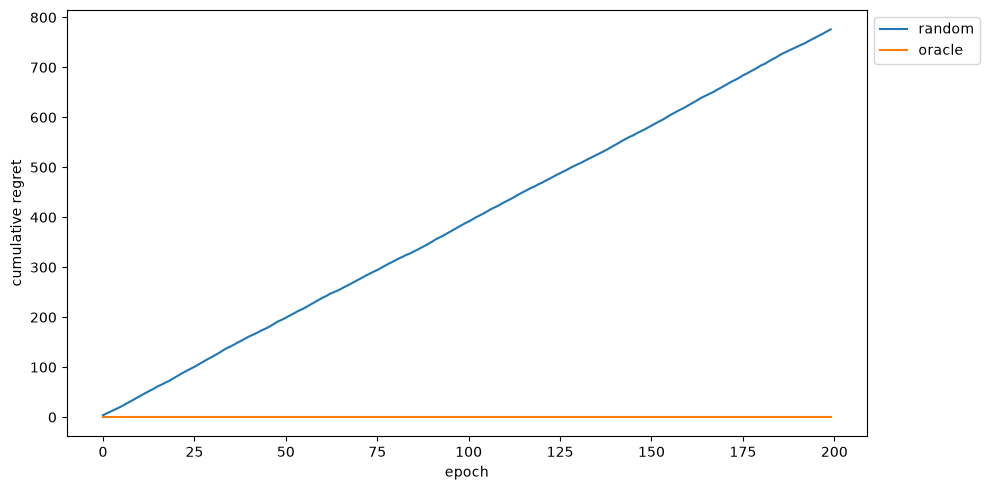

In [9]:
# skumulowany regret

runner.plot_results(results, mode='regret')

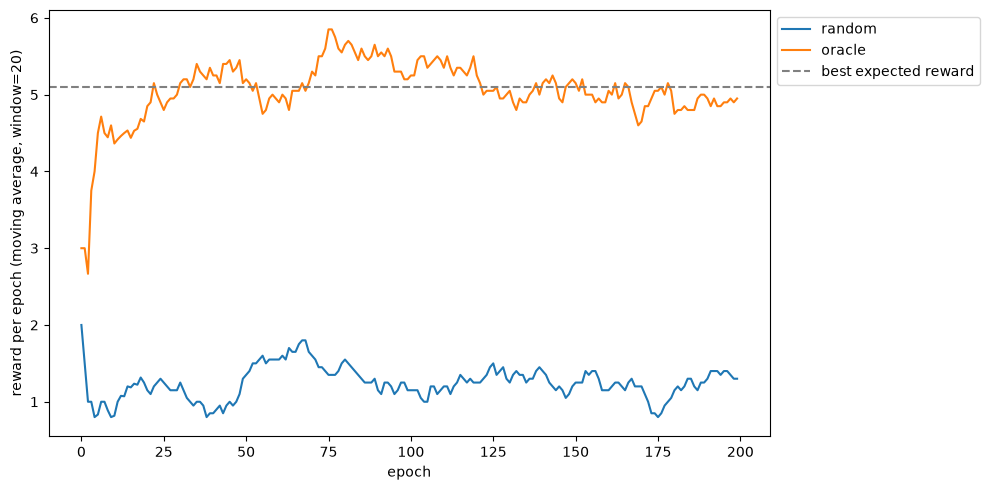

In [10]:
# reward (liczba klikniec) per epoka

runner.plot_results(results, mode='reward')

## Część 2. - ε-greedy

In [11]:
# statystyki, ktore bandyta zbiera o jednym ramieniu - uzyjemy ich we wszystkich bandytach

@dataclass
class ArmStats:
    trials: int = 0     # ile razy ramie bylo rekomendowane
    successes: int = 0  # ile razy zostalo klikniete

    @property
    def failures(self) -> int:
        return self.trials - self.successes

    @property
    def mean(self) -> float:  # srednia nagroda - empiryczny CTR
        return self.successes / self.trials if self.trials > 0 else 0.0

    def update(self, reward: int) -> None:
        self.trials += 1
        self.successes += reward

In [12]:
class EGreedy(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], epsilon: float):
        super().__init__(bandit_id, arm_ids)
        self.epsilon = epsilon
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        n_random = sum(random() < self.epsilon for _ in range(size))
        best = sorted(self.arm_ids, key=lambda arm_id: self.stats[arm_id].mean, reverse=True)[:size - n_random]
        rest = [arm_id for arm_id in self.arm_ids if arm_id not in best]
        return best + sample(rest, n_random)

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [13]:
# porownujemy kilka wartosci epsilon

bandits = [EGreedy(f'egreedy_{epsilon}', arm_ids, epsilon) for epsilon in [0, 0.05, 0.25, 0.5]]

runner = Runner(arms, bandits)
results = runner.simulate(EPOCHS, RECOMMENDATION_SIZE)
runner.print_summary(results)

Simulating: egreedy_0
Simulating: egreedy_0.05
Simulating: egreedy_0.25
Simulating: egreedy_0.5

bandit                 total reward   total regret
egreedy_0.25                    625          381.9
egreedy_0.5                     609          403.9
egreedy_0.05                    466          564.2
egreedy_0                       241          775.0


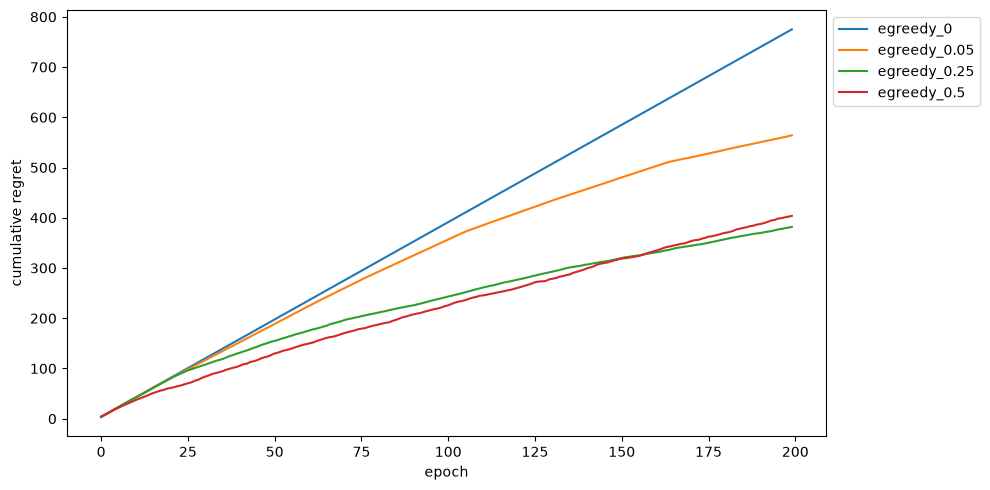

In [14]:
runner.plot_results(results, mode='regret')

In [15]:
# mozemy sprawdzic, jaka wiedze bandyta zdobyl o poszczegolnych ramionach

trained = next(bandit for bandit in bandits if bandit.bandit_id == 'egreedy_0.25')
top_arms = sorted(arm_ids, key=lambda arm_id: trained.stats[arm_id].mean, reverse=True)[:RECOMMENDATION_SIZE]

print(f"{'arm':<12}{'trials':>8}{'successes':>11}{'mean':>7}{'true CTR':>10}")
for arm_id in top_arms:
    stats = trained.stats[arm_id]
    print(f'{arm_id:<12}{stats.trials:>8}{stats.successes:>11}{stats.mean:>7.2f}{arms[arm_id].click_probability:>10.2f}')

arm           trials  successes   mean  true CTR
top_0             66         43   0.65      0.63
top_4            175        110   0.63      0.65
top_2            126         73   0.58      0.56
top_3            156         85   0.54      0.54
good_9           176         78   0.44      0.43
good_3           129         50   0.39      0.38
average_8        117         38   0.32      0.27
average_33       121         38   0.31      0.29
good_2            16          5   0.31      0.32
average_1         61         18   0.30      0.24


## Część 3. - UCB (Upper Confidence Bound)

In [16]:
class UCB(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], optimism_weight: float):
        super().__init__(bandit_id, arm_ids)
        self.optimism_weight = optimism_weight
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}
        self.total_trials = 0

    def score(self, stats: ArmStats) -> float:
        if stats.trials == 0:
            return inf
        return stats.mean + self.optimism_weight * sqrt(log(self.total_trials) / stats.trials)

    def recommend(self, size: int) -> List[str]:
        return sorted(self.arm_ids, key=lambda arm_id: self.score(self.stats[arm_id]), reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)
        self.total_trials += 1

In [17]:
bandits = [UCB(f'ucb_{optimism_weight}', arm_ids, optimism_weight) for optimism_weight in [0.01, 0.1, 0.3, 1]]

runner = Runner(arms, bandits)
results = runner.simulate(EPOCHS, RECOMMENDATION_SIZE)
runner.print_summary(results)

Simulating: ucb_0.01
Simulating: ucb_0.1
Simulating: ucb_0.3
Simulating: ucb_1

bandit                 total reward   total regret
ucb_0.01                        648          354.6
ucb_0.3                         634          390.8
ucb_0.1                         601          410.7
ucb_1                           335          658.2


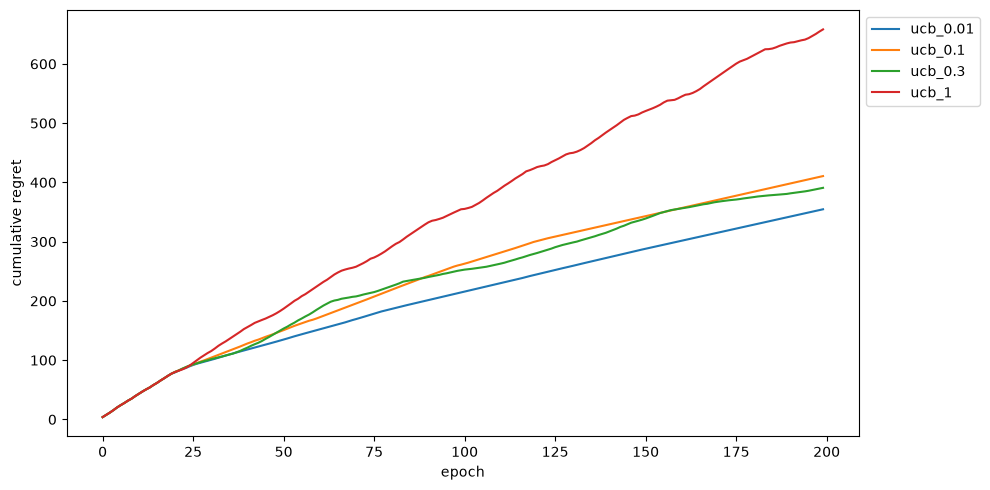

In [18]:
runner.plot_results(results, mode='regret')

## Część 4. - Thompson Sampling

In [19]:
class ThompsonSampling(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], reward_multiplier: float, regret_multiplier: float):
        super().__init__(bandit_id, arm_ids)
        self.reward_multiplier = reward_multiplier
        self.regret_multiplier = regret_multiplier
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def sample_ctr(self, stats: ArmStats) -> float:
        return betavariate(1 + self.reward_multiplier * stats.successes, 1 + self.regret_multiplier * stats.failures)

    def recommend(self, size: int) -> List[str]:
        samples = {arm_id: self.sample_ctr(self.stats[arm_id]) for arm_id in self.arm_ids}
        return sorted(self.arm_ids, key=samples.get, reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [20]:
bandits = [ThompsonSampling(f'ts_{reward_multiplier}_{regret_multiplier}', arm_ids, reward_multiplier, regret_multiplier)
           for reward_multiplier, regret_multiplier in [(1, 1), (10, 10), (1, 10), (10, 1)]]

runner = Runner(arms, bandits)
results = runner.simulate(EPOCHS, RECOMMENDATION_SIZE)
runner.print_summary(results)

Simulating: ts_1_1
Simulating: ts_10_10
Simulating: ts_1_10
Simulating: ts_10_1

bandit                 total reward   total regret
ts_10_10                        767          254.5
ts_10_1                         563          461.5
ts_1_10                         505          500.2
ts_1_1                          511          515.1


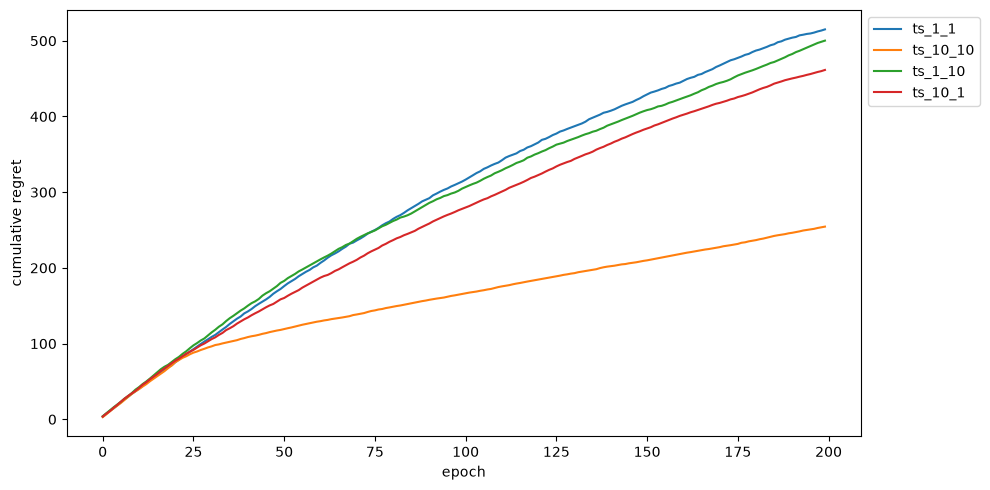

In [21]:
runner.plot_results(results, mode='regret')

## Część 5. - Własny bandyta

Zaimplementuj własny algorytm bandyty. Może to być np. bandyta Softmax, Thompson Sampling z dwoma rozkładami beta, Thompson Sampling z rozkładem innnym niż beta lub cokolwiek innego, co ci przyjdzie do głowy.

In [22]:
# Thompson Sampling z dwoma rozkladami beta:
#  1) wspolny rozklad "jaki CTR maja ramiona przecietnie" - uczony na kliknieciach ze wszystkich ramion
#  2) rozklad kazdego ramienia, ktory startuje z rozkladu 1) zamiast z jednostajnego Beta(1, 1)

class CustomBandit(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], prior_strength: float, reward_multiplier: float, regret_multiplier: float):
        super().__init__(bandit_id, arm_ids)
        self.reward_multiplier = reward_multiplier
        self.regret_multiplier = regret_multiplier
        self.prior_strength = prior_strength
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}
        self.global_stats = ArmStats()

    def recommend(self, size: int) -> List[str]:
        global_ctr = (1 + self.global_stats.successes) / (2 + self.global_stats.trials)
        prior_a = global_ctr * self.prior_strength
        prior_b = (1 - global_ctr) * self.prior_strength
        samples = {arm_id: betavariate(prior_a + self.reward_multiplier * stats.successes, prior_b + self.regret_multiplier * stats.failures)
                    for arm_id, stats in self.stats.items()}
        return sorted(self.arm_ids, key=samples.get, reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)
        self.global_stats.update(reward)

In [23]:
bandits = [CustomBandit(f'ts2_{prior_strength}', arm_ids, prior_strength, 10, 10) for prior_strength in [0.1, 1, 5, 20]]

runner = Runner(arms, bandits)
results = runner.simulate(EPOCHS, RECOMMENDATION_SIZE)
runner.print_summary(results)

Simulating: ts2_0.1
Simulating: ts2_1
Simulating: ts2_5
Simulating: ts2_20

bandit                 total reward   total regret
ts2_20                          800          211.9
ts2_1                           847          221.4
ts2_0.1                         770          249.2
ts2_5                           725          251.7


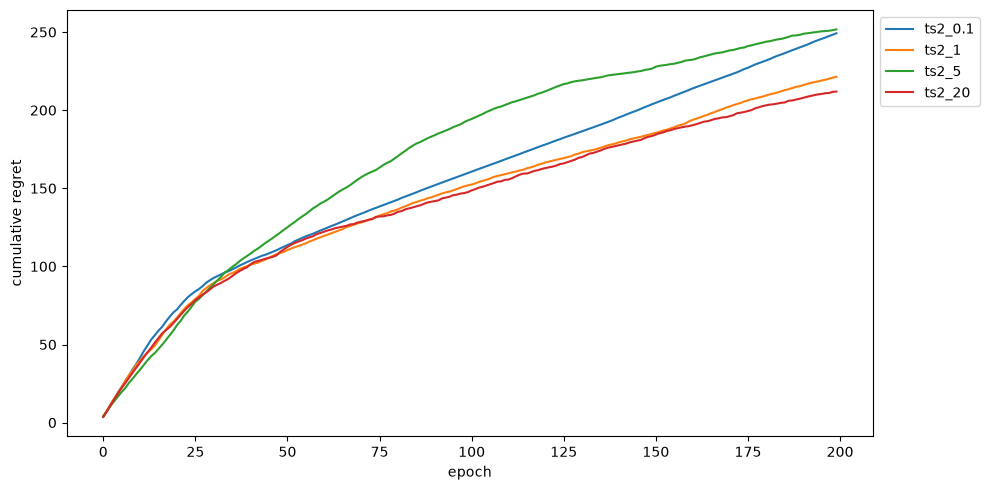

In [24]:
runner.plot_results(results, mode='regret')

## Część 6. - porównanie bandytów

In [25]:
# tworzymy nowych bandytow na potrzeby porowwnania
# mozesz wykorzystac parametry znalezione na wczesniejszych etapach lub przetestowac nowe
bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms),
    EGreedy('egreedy', arm_ids, epsilon=0.05),
    UCB('ucb', arm_ids, optimism_weight=0.1),
    ThompsonSampling('ts', arm_ids, reward_multiplier=10, regret_multiplier=10),
    CustomBandit('ts2', arm_ids, prior_strength=5, reward_multiplier=10, regret_multiplier=10),
]

runner = Runner(arms, bandits)
results = runner.simulate(EPOCHS, RECOMMENDATION_SIZE)
runner.print_summary(results)

Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: ts2

bandit                 total reward   total regret
oracle                         1019            0.0
ts                              720          279.8
ts2                             668          335.8
ucb                             650          362.6
egreedy                         518          514.2
random                          246          775.7


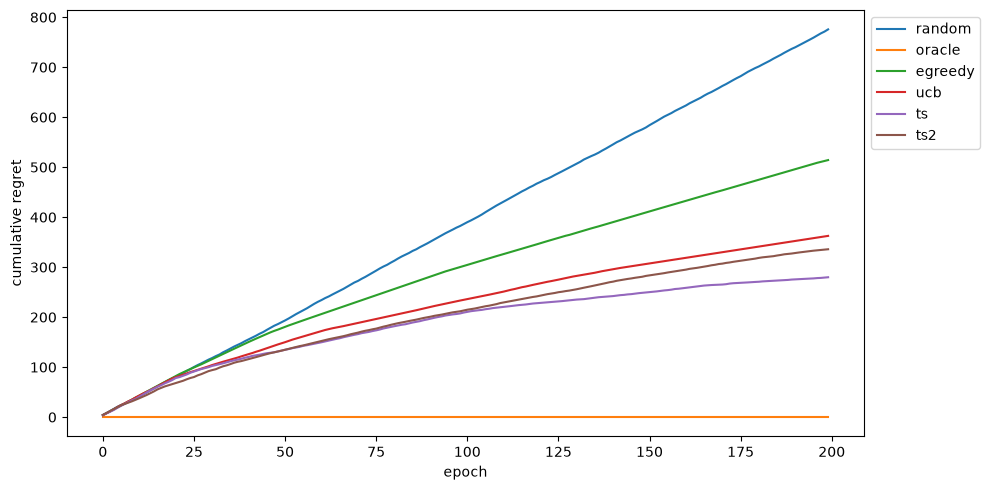

In [26]:
runner.plot_results(results, mode='regret')

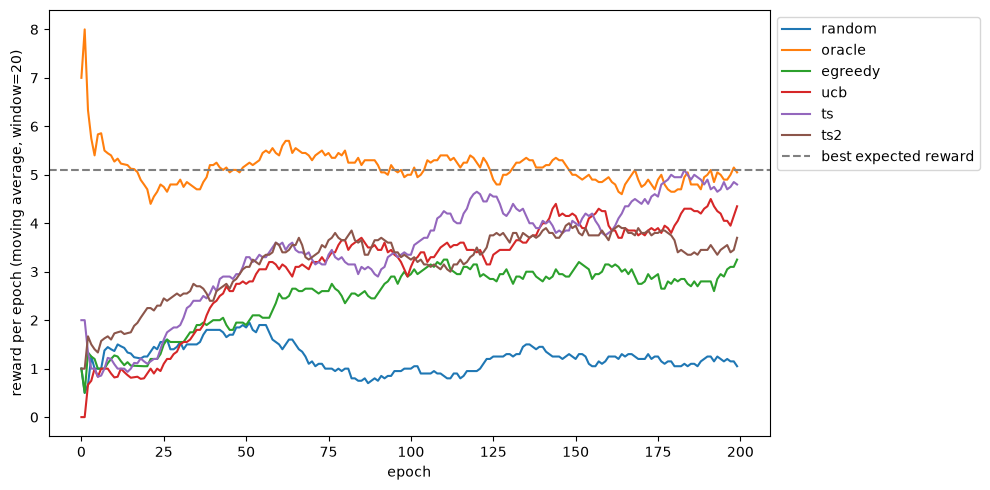

In [27]:
runner.plot_results(results, mode='reward')